# Scaled dot-product and masked attention

Four library records contain a city or a year. A query retrieves a weighted average of the records it can see. One deliberately empty row makes the masking convention explicit.

Attention normalises QKᵀ/√d over allowed keys. Subtracting the largest finite logit stabilises the exponential. An empty query row returns zero attention and a zero output in this implementation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def report(columns, rows):
    frame = pd.DataFrame(rows, columns=columns)
    try:
        from IPython import get_ipython

        interactive = get_ipython() is not None
    except ImportError:
        interactive = False
    if interactive:
        from IPython.display import display

        display(frame.round(5))
    else:
        print(frame.round(5).to_string(index=False))


def attention(q, k, v, allowed):
    scores = q @ k.T / np.sqrt(q.shape[-1])
    active = allowed.any(axis=-1, keepdims=True)
    masked = np.where(allowed, scores, -np.inf)
    peak = np.where(active, masked.max(axis=-1, keepdims=True), 0.0)
    w = np.exp(masked - peak)
    total = w.sum(axis=-1, keepdims=True)
    w = np.divide(w, total, out=np.zeros_like(w), where=total > 0)
    return w, w @ v

## Inspect retrieval and masking

The third query has no available key. Modify a forbidden value and test that neither of the last two query outputs changes.

In [2]:
q = np.array([[2.0, 0.0], [0.0, 3.0], [1.0, 1.0]])
k = np.array([[1.0, 0.0], [0.8, 0.2], [0.0, 1.0], [0.1, 0.9]])
v = np.array([[1.0, 0.0], [0.7, 0.3], [0.0, 1.0], [0.2, 0.8]])
allowed = np.array([[1, 1, 1, 1], [0, 0, 1, 1], [0, 0, 0, 0]], dtype=bool)
w, out = attention(q, k, v, allowed)
changed = v.copy()
changed[0] += 100
assert np.allclose(attention(q, k, changed, allowed)[1][1:], out[1:])
assert np.allclose(w.sum(1), [1, 1, 0])
report(
    ["Query", "Allowed keys", "Sum of weights", "City output", "Year output"],
    [
        (n, int(a.sum()), r.sum(), *o)
        for n, a, r, o in zip(["City", "Year", "Empty"], allowed, w, out)
    ],
)

,Query,Allowed keys,Sum of weights,City output,Year output
0,City,4,1.0,0.69552,0.30448
1,Year,2,1.0,0.08943,0.91057
2,Empty,0,0.0,0.00000,0.00000


## Read the attention matrix

The values in each allowed row sum to one. A zero in the final row records an empty selection.

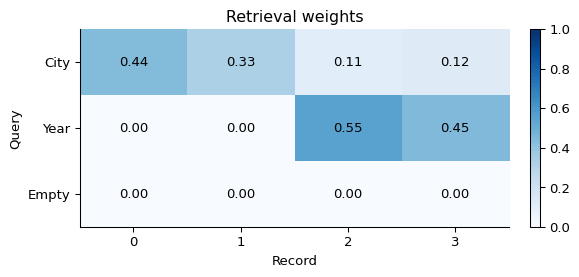

In [3]:
fig, ax = plt.subplots(figsize=(6, 2.8), layout="constrained")
im = ax.imshow(w, vmin=0, vmax=1, cmap="Blues", aspect="auto")
for (i, j), value in np.ndenumerate(w):
    ax.text(j, i, f"{value:.2f}", ha="center", va="center")
ax.set(
    xticks=range(4),
    yticks=range(3),
    yticklabels=["City", "Year", "Empty"],
    xlabel="Record",
    ylabel="Query",
    title="Retrieval weights",
)
fig.colorbar(im, ax=ax)
plt.show()

## Interpreting the result

The second query cannot read either city record. The perturbation test checks that restriction at the output, where a masking error would otherwise be easy to miss.

## Exercise

Double the query magnitudes and compare the entropy of the two non-empty rows.

## References

[Vaswani et al. (2017), Attention Is All You Need](https://arxiv.org/abs/1706.03762)